## **UTS Graf Sains Data**

**Nama:** Nailah Masruroh  
**NIM:** 23031554100  
**Kelas:** 2023E

##### **Setup environment (dijalankan di terminal, bukan di notebook)**
```bash
python -m venv myenv            # atau: uv venv myenv --python 3.10
source myenv/bin/activate       # Windows: myenv\Scripts\activate
pip install neo4j pandas numpy scipy networkx matplotlib tqdm jupyter ipykernel
```
> **Catatan versi driver:** `requirements.txt` soal memakai `neo4j==4.2.1`, yang hanya cocok untuk **server Neo4j 4.x**. Jika Neo4j Desktop Anda versi **5.x**, pakai `pip install "neo4j>=5"`. 

**Unduh dataset** (Kaggle biasanya butuh login, jadi cara paling aman):
```bash
pip install kaggle   # taruh kaggle.json di ~/.kaggle/
kaggle datasets download -d retailrocket/ecommerce-dataset -p data --unzip
```
atau unduh manual dari halaman Kaggle `retailrocket/ecommerce-dataset`, ekstrak `events.csv` ke `data/`.

##### **Jawaban Pertanyaan Pendahuluan (Bagian 1.2)**
1. **Nama database:** `neo4j` (`database_="neo4j"`, default database Neo4j).
2. **Akses database lain dalam 1 instance:** ganti parameter `database_=` / `driver.session(database="namadb")`, atau di Cypher memakai `USE namadb MATCH ...` (di Browser: `:use namadb`); daftar database: `SHOW DATABASES` (via database `system`). *(Multi-database penuh hanya di Enterprise; Community hanya `neo4j` + `system`.)*
3. **Jenis graf:** *directed graph* (relasi `KNOWS` berarah Arthur → teman), tanpa bobot, *simple graph* (`MERGE` mencegah duplikat), dengan satu label simpul `Person`; bentuknya *out-star* dengan Arthur sebagai pusat.

In [1]:
import os, math, getpass
from pathlib import Path
import numpy as np, pandas as pd, scipy.sparse as sp, networkx as nx, matplotlib.pyplot as plt
from tqdm.auto import tqdm
from neo4j import GraphDatabase
from IPython.display import display, Image as DisplayImage, Markdown
from PIL import Image


# ===== KONFIGURASI =====
DATA_DIR = Path("data"); EVENTS_CSV = DATA_DIR / "events.csv"

P1_START, P1_END = "2015-05-13", "2015-08-01"   # training
P2_START, P2_END = "2015-08-02", "2015-08-22"   # testing
MIN_EVENTS_P1, BATCH_SIZE = 3, 5000
BOLT_URI, NEO_USER, NEO_DB = "bolt://localhost:7687", "neo4j", "neo4j"
NEO_PASS = os.getenv("NEO4J_PASSWORD") or getpass.getpass("Password Neo4j: ")
RESET_DB = True          # hapus isi DB sebelum impor (hati-hati di shared DB)
SEED, K = 2026, 5

driver = GraphDatabase.driver(BOLT_URI, auth=(NEO_USER, NEO_PASS)); driver.verify_connectivity()
def cypher(q, **p):
    with driver.session(database=NEO_DB) as s: return [r.data() for r in s.run(q, **p)]
R = "VIEWED|ADDED_TO_CART|BOUGHT"

##### **2.1 Wrangling dan EDA**

**No. 1 & 2: Filter 2 periode dan simpan ke CSV**

Timestamp (ms) dikonversi ke datetime lalu difilter menjadi P1 (training) dan P2 (testing). Hanya visitor dengan ≥ `MIN_EVENTS_P1` event di P1 yang dipakai. P1 masuk Neo4j, sedangkan P2 menjadi *ground truth* evaluasi.

In [2]:
raw = pd.read_csv(EVENTS_CSV); 
raw["ts"] = pd.to_datetime(raw["timestamp"], unit="ms")
print(raw.shape, raw.ts.min(), "->", raw.ts.max())

cut = lambda d, a, b: d[(d.ts >= pd.Timestamp(a)) & (d.ts < pd.Timestamp(b) + pd.Timedelta(days=1))].copy()
assert pd.Timestamp(P1_END) < pd.Timestamp(P2_START)
p1, p2 = cut(raw, P1_START, P1_END), cut(raw, P2_START, P2_END)
cnt = p1.groupby("visitorid").size(); aktif = cnt[cnt >= MIN_EVENTS_P1].index
p1, p2 = p1[p1.visitorid.isin(aktif)], p2[p2.visitorid.isin(aktif)]

DATA_DIR.mkdir(exist_ok=True)
for name, d in [("P1_train", p1), ("P2_test", p2)]:
    o = d[["timestamp","visitorid","event","itemid","transactionid"]].copy()
    o["transactionid"] = o["transactionid"].astype("Int64"); o.to_csv(DATA_DIR / f"events_{name}.csv", index=False)
    print(name, len(d), "baris |", d.visitorid.nunique(), "visitor |", d.itemid.nunique(), "item")

(2756101, 6) 2015-05-03 03:00:04.384000 -> 2015-09-18 02:59:47.788000
P1_train 843808 baris | 124711 visitor | 102913 item
P2_test 34751 baris | 6148 visitor | 15508 item


**Impor P1 ke Neo4j (batch, `UNWIND` per jenis event).**

In [3]:
EVENT_REL = {"view": "VIEWED", "addtocart": "ADDED_TO_CART", "transaction": "BOUGHT"}
def q_import(rel):
    ex = ", transactionId: row.transactionid" if rel == "BOUGHT" else ""
    return f"""UNWIND $batch AS row
    MERGE (v:Visitor {{visitorId: row.visitorid}}) MERGE (i:Item {{itemId: row.itemid}})
    CREATE (v)-[:{rel} {{timestamp: row.timestamp{ex}}}]->(i)"""
QI = {e: q_import(r) for e, r in EVENT_REL.items()}

if RESET_DB:
    while cypher("MATCH (n) WITH n LIMIT 50000 DETACH DELETE n RETURN count(*) AS c")[0]["c"] > 0: pass
for q in ["CREATE CONSTRAINT visitor_id IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE",
          "CREATE CONSTRAINT item_id IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE"]:
    cypher(q) 

with driver.session(database=NEO_DB) as s:
    for ch in tqdm(pd.read_csv(DATA_DIR / "events_P1_train.csv", chunksize=BATCH_SIZE), total=len(p1)//BATCH_SIZE+1):
        for ev, g in ch.groupby("event"):
            recs = [{"visitorid": int(v), "itemid": int(i), "timestamp": int(t), "transactionid": int(x) if pd.notna(x) else None}
                    for v, i, t, x in zip(g.visitorid, g.itemid, g.timestamp, g.transactionid)]
            s.run(QI[ev], batch=recs).consume()

  0%|          | 0/169 [00:00<?, ?it/s]

**No. 3: Komposisi subgraph (jenis & jumlah simpul)**

`MATCH (n)` + `UNWIND labels(n)` memecah label tiap simpul, `count(*)` menghitung per jenis. `MATCH ()-[r]->()` + `type(r)` menghitung relasi per jenis.

In [4]:
Q_NODES = "MATCH (n) UNWIND labels(n) AS label RETURN label, count(*) AS jumlah ORDER BY jumlah DESC"
Q_RELS  = "MATCH ()-[r]->() RETURN type(r) AS relasi, count(*) AS jumlah ORDER BY jumlah DESC"
print("Jenis & jumlah simpul:");  display(pd.DataFrame(cypher(Q_NODES)))
print("Jenis & jumlah relasi:");  display(pd.DataFrame(cypher(Q_RELS)))

Jenis & jumlah simpul:


,label,jumlah
0,Visitor,124711
1,Item,102913


Jenis & jumlah relasi:


,relasi,jumlah
0,VIEWED,793197
1,ADDED_TO_CART,36931
2,BOUGHT,13680


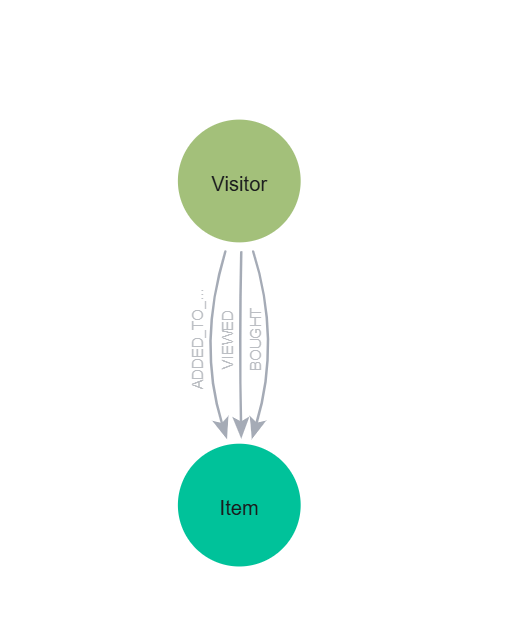

In [5]:
display(DisplayImage(filename="images/skema_graf.png", width=500))

**No. 4 & 5: VSM User dan VSM Item**

**VSM User** = tiap visitor direpresentasikan sebagai vektor di ruang item (matriks `A` user×item, biner).  
**VSM Item** = tiap item direpresentasikan sebagai vektor di ruang visitor (`Aᵀ` item×user).

VSM User: shape=(124711, 102913) | dimensi vektor=102,913 (item) | jumlah vektor=124,711 (visitor) | Non-zero=511,584 | sparsity=99.9960% | derajat min/median/mean/max=1/3/4.1/2584 | dense=102.68 GB
VSM Item: shape=(102913, 124711) | dimensi vektor=124,711 (visitor) | jumlah vektor=102,913 (item) | Non-zero=511,584 | sparsity=99.9960% | derajat min/median/mean/max=1/2/5.0/539 | dense=102.68 GB


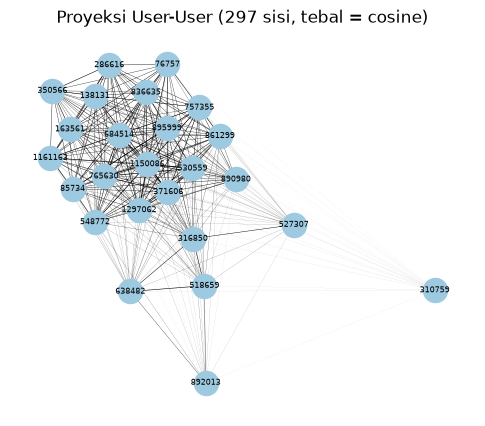

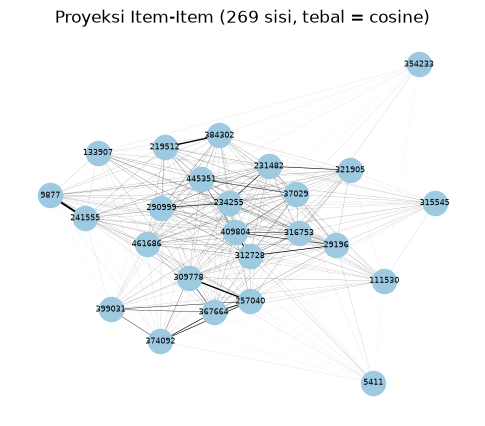

In [6]:
Q_EDGES = f"MATCH (v:Visitor)-[r:{R}]->(i:Item) RETURN v.visitorId AS u, i.itemId AS i, count(*) AS n"
pairs = pd.DataFrame(cypher(Q_EDGES))
uc, uu = pd.factorize(pairs["u"], sort=True); ic, iu = pd.factorize(pairs["i"], sort=True)
user_ids, item_ids = np.asarray(uu), np.asarray(iu)
A = sp.csr_matrix((np.ones(len(pairs)), (uc, ic)), shape=(len(user_ids), len(item_ids)))   # user x item
AT = A.T.tocsr()                                                                             # item x user

def desc(M, name, rows, cols):
    r, c = M.shape; deg = np.diff(M.indptr)
    print(f"{name}: shape={M.shape} | dimensi vektor={c:,} ({cols}) | jumlah vektor={r:,} ({rows}) | Non-zero={M.nnz:,} | "
          f"sparsity={1-M.nnz/(r*c):.4%} | derajat min/median/mean/max={deg.min()}/{np.median(deg):.0f}/{deg.mean():.1f}/{deg.max()} | dense={r*c*8/1e9:.2f} GB")
desc(A, "VSM User", "visitor", "item"); desc(AT, "VSM Item", "item", "visitor")

def plot_proj(M, ids, title, n=25):
    deg = np.diff(M.indptr); idx = np.argsort(-deg, kind="stable")[:n]
    sub = M[idx]; nr = np.sqrt(deg[idx].astype(float)); cos = (sub @ sub.T).toarray() / np.outer(nr, nr)
    G = nx.Graph(); G.add_nodes_from(range(n))
    G.add_weighted_edges_from((a, b, cos[a, b]) for a in range(n) for b in range(a+1, n) if cos[a, b] > 0)
    pos = nx.spring_layout(G, seed=SEED, weight="weight")
    plt.figure(figsize=(6, 5)); nx.draw_networkx(G, pos, node_size=300, node_color="#9ecae1", font_size=6,
        width=[3*d["weight"] for *_, d in G.edges(data=True)], labels={k: str(ids[idx[k]]) for k in G.nodes})
    plt.title(f"{title} ({G.number_of_edges()} sisi, tebal = cosine)"); plt.axis("off"); plt.show()
plot_proj(A, user_ids, "Proyeksi User-User"); plot_proj(AT, item_ids, "Proyeksi Item-Item")

In [7]:
du, di = np.diff(A.indptr), np.diff(AT.indptr)
sparsity = 1 - A.nnz / (A.shape[0] * A.shape[1])
dense_gb = A.shape[0] * A.shape[1] * np.dtype(A.dtype).itemsize / 1e9
display(Markdown(f"""
**Karakteristik VSM User dan Item.** Matriks User memiliki shape
`{A.shape}`: {A.shape[0]:,} visitor, masing-masing berupa vektor berdimensi
{A.shape[1]:,} item. Matriks Item merupakan transposenya, dengan shape
`{AT.shape}` dan dimensi vektor {AT.shape[1]:,} visitor. Nilai 1 berarti ada
minimal satu interaksi P1; frekuensi dan jenis event tidak dibedakan dalam VSM biner ini.

Sparsity kedua matriks adalah **{sparsity:.6%}**. Penyimpanan dense dengan
dtype `{A.dtype}` membutuhkan sekitar **{dense_gb:.2f} GB** per matriks,
sehingga representasi sparse CSR lebih sesuai.

Derajat menyatakan jumlah tetangga unik, bukan jumlah event.
Untuk user: median **{np.median(du):g}**, maksimum **{du.max():,}**;
untuk item: median **{np.median(di):g}**, maksimum **{di.max():,}**.
Perbedaan median dan maksimum memperlihatkan ketimpangan aktivitas dan popularitas.

Setiap plot hanya menampilkan **25 simpul berderajat tertinggi** pada proyeksi
terkait, bukan seluruh graf. Sisi muncul jika cosine positif; ketebalan sisi
sebanding dengan cosine. Posisi dari spring layout membantu visualisasi dan
bukan ukuran similarity secara langsung. Plot simpul teraktif tidak mewakili
seluruh distribusi pengguna/item.
"""))


**Karakteristik VSM User dan Item.** Matriks User memiliki shape
`(124711, 102913)`: 124,711 visitor, masing-masing berupa vektor berdimensi
102,913 item. Matriks Item merupakan transposenya, dengan shape
`(102913, 124711)` dan dimensi vektor 124,711 visitor. Nilai 1 berarti ada
minimal satu interaksi P1; frekuensi dan jenis event tidak dibedakan dalam VSM biner ini.

Sparsity kedua matriks adalah **99.996014%**. Penyimpanan dense dengan
dtype `float64` membutuhkan sekitar **102.68 GB** per matriks,
sehingga representasi sparse CSR lebih sesuai.

Derajat menyatakan jumlah tetangga unik, bukan jumlah event.
Untuk user: median **3**, maksimum **2,584**;
untuk item: median **2**, maksimum **539**.
Perbedaan median dan maksimum memperlihatkan ketimpangan aktivitas dan popularitas.

Setiap plot hanya menampilkan **25 simpul berderajat tertinggi** pada proyeksi
terkait, bukan seluruh graf. Sisi muncul jika cosine positif; ketebalan sisi
sebanding dengan cosine. Posisi dari spring layout membantu visualisasi dan
bukan ukuran similarity secara langsung. Plot simpul teraktif tidak mewakili
seluruh distribusi pengguna/item.


**Fungsi bantu: similarity, KNN, dan metrik**

Cosine dihitung dari vektor interaksi biner. Tetangga diurutkan berdasarkan
cosine menurun, lalu ID menaik saat skor seri. Urutan ini sama di Python dan Cypher.

Evaluasi menggunakan rekomendasi item baru bagi user: ground truth adalah
item unik P2 yang ada di katalog P1, dikurangi semua item yang pernah
diinteraksikan user tersebut pada P1. Aturan ini sesuai dengan rekomendasi
yang membuang item yang sudah dilihat. User tanpa ground truth tersisa
dikeluarkan dari evaluasi. Item cold-start di luar katalog P1 tidak dievaluasi.
KNN k=5 menghasilkan top-5 untuk metrik; tiga teratas dipakai sebagai iklan.

In [8]:
def make_topk(M):
    M = M.tocsr(); MT = M.T.tocsr(); deg = np.diff(M.indptr); norm = np.sqrt(deg.astype(float))
    def topk(rows, k=K, chunk=500):
        out = {}
        for s in range(0, len(rows), chunk):
            r = np.asarray(rows[s:s+chunk]); P = (M[r] @ MT).tocsr()
            for a, ri in enumerate(r):
                c, x = P.indices[P.indptr[a]:P.indptr[a+1]], P.data[P.indptr[a]:P.indptr[a+1]]
                keep = c != ri; c, x = c[keep], x[keep]; sc = x / (norm[ri] * norm[c])
                o = np.lexsort((c, -sc))[:k]; out[int(ri)] = [(int(c[j]), float(sc[j])) for j in o]
        return out
    return topk
TOPK = {"Visitor": make_topk(A), "Item": make_topk(AT)}
pop_order = np.argsort(-np.diff(AT.indptr), kind="stable")                 # item terpopuler (fallback)

def recommend(u_row, mode, k=K, n_rec=5):
    seen = set(A[u_row].indices.tolist()); sc = {}
    if mode == "Item":                      # item-based KNN
        for lst in TOPK["Item"](sorted(seen), k=k).values():
            for it, s in lst:
                if it not in seen: sc[it] = sc.get(it, 0) + s
    else:                                   # user-based KNN
        for nb, s in TOPK["Visitor"]([u_row], k=k)[u_row]:
            for it in A[nb].indices:
                if it not in seen: sc[it] = sc.get(it, 0) + s
    top = sorted(sc.items(), key=lambda x: (-x[1], x[0]))[:n_rec]
    for it in pop_order:                    # fallback bila kandidat KNN < n_rec (skor 0)
        if len(top) >= n_rec: break
        if it not in seen and it not in dict(top): top.append((int(it), 0.0))
    return [(int(item_ids[i]), s) for i, s in top]

def metrics(ids, rel, n=5):
    rp = [int(i in rel) for i in ids[:n]]
    dcg = sum(r / math.log2(p + 2) for p, r in enumerate(rp)); idcg = sum(1 / math.log2(p + 2) for p in range(min(len(rel), n)))
    return rp, int(any(rp)), (dcg / idcg if idcg else 0.0), dcg, idcg

# user_ids dan item_ids dihasilkan oleh factorize(sort=True), sehingga
# tie-break indeks menaik sama dengan ID asli menaik.
assert np.all(user_ids[:-1] < user_ids[1:])
assert np.all(item_ids[:-1] < item_ids[1:])
known = set(map(int, item_ids))
urow_by_id = {int(uid): row for row, uid in enumerate(user_ids)}
GT = {}
gt_audit = dict(user_p2=0, unique_p2=0, outside_catalog=0, seen_p1=0)
for uid, group in p2.groupby("visitorid"):
    uid = int(uid)
    if uid not in urow_by_id:
        continue
    gt_audit["user_p2"] += 1
    p2_items = set(map(int, group["itemid"]))
    in_catalog = p2_items & known
    seen = set(map(int, item_ids[A[urow_by_id[uid]].indices]))
    gt_audit["unique_p2"] += len(p2_items)
    gt_audit["outside_catalog"] += len(p2_items - known)
    gt_audit["seen_p1"] += len(in_catalog & seen)
    relevant_items = in_catalog - seen
    if relevant_items:
        GT[uid] = relevant_items
cand = np.array(sorted(GT), dtype=user_ids.dtype)
print("Audit ground truth (hitungan pasangan user-item):", gt_audit)
print("User dievaluasi:", len(cand))
print("User P2 tanpa ground truth layak:", gt_audit["user_p2"] - len(cand))
if not len(cand):
    raise ValueError("Ground truth kosong; periksa periode dan filter sebelum evaluasi.")

Audit ground truth (hitungan pasangan user-item): {'user_p2': 6148, 'unique_p2': 22606, 'outside_catalog': 3773, 'seen_p1': 3269}
User dievaluasi: 4244
User P2 tanpa ground truth layak: 1904


**No. 6: Proyeksi mana yang lebih baik (efektif/efisien)?**

**Efisiensi:** jumlah simpul dan batas atas sisi `Σ C(d,2)` (pasangan yang berbagi ≥1 tetangga).  
**Efektivitas:** rata-rata Hit@5 dan NDCG@5 pada seluruh user yang punya ground truth untuk KNN berbasis masing-masing proyeksi.

In [9]:
du, di = np.diff(A.indptr).astype(np.int64), np.diff(AT.indptr).astype(np.int64)
st = lambda n, d: (n, min(int((d*(d-1)//2).sum()), n*(n-1)//2), n*n*8/1e9)
eff = pd.DataFrame([("Visitor",)+st(A.shape[0], di), ("Item",)+st(A.shape[1], du)], columns=["Proyeksi", "Jumlah simpul", "Batas atas sisi", "Dense GB"])
eval_u = cand   
for mode in ["Visitor", "Item"]:
    res = [metrics([i for i, _ in recommend(int(np.searchsorted(user_ids, u)), mode)], GT[int(u)]) for u in tqdm(eval_u, desc=mode)]
    eff.loc[eff.Proyeksi == mode, ["Hit@5", "NDCG@5"]] = [np.mean([r[1] for r in res]), np.mean([r[2] for r in res])]
eff["Jumlah user evaluasi"] = len(eval_u)
display(eff)
PROYEKSI = eff.sort_values(["Hit@5", "NDCG@5"], ascending=False).iloc[0]["Proyeksi"]      # pilih yang paling efektif
print("Paling efisien (sisi kandidat paling sedikit):", eff.loc[eff["Batas atas sisi"].idxmin(), "Proyeksi"])
print("Paling efektif (Hit@5/NDCG@5)               :", PROYEKSI, "-> dipakai untuk similarity & KNN")

Visitor:   0%|          | 0/4244 [00:00<?, ?it/s]

Item:   0%|          | 0/4244 [00:00<?, ?it/s]

,Proyeksi,Jumlah simpul,Batas atas sisi,Dense GB,Hit@5,NDCG@5,Jumlah user evaluasi
0,Visitor,124711,6967511,124.422668,0.034637,0.015648,4244
1,Item,102913,18106789,84.728685,0.032752,0.014904,4244


Paling efisien (sisi kandidat paling sedikit): Visitor
Paling efektif (Hit@5/NDCG@5)               : Visitor -> dipakai untuk similarity & KNN


**Interpretasi perbandingan proyeksi**

Batas atas sisi dihitung dari jumlah pasangan tetangga bersama dan dibatasi
jumlah pasangan simpul maksimum. Pasangan dapat terhitung berulang, sehingga
angka ini bukan jumlah sisi aktual atau pengukuran waktu komputasi.
Memori dense adalah estimasi jika matriks similarity penuh disimpan sebagai float64.

Proyeksi dipilih dengan Hit@5 tertinggi, lalu NDCG@5 sebagai pembeda.
Ini adalah pemilihan eksploratif memakai P2, sehingga metrik P2 bukan estimasi
uji independen setelah pemilihan model. Untuk pengujian independen diperlukan
periode validasi dan testing terpisah. Tidak ada klaim signifikansi statistik.
Kesimpulan numerik terbaru dicetak oleh sel berikut.

In [10]:
best = eff.set_index("Proyeksi").loc[PROYEKSI]
least_bound = eff.loc[eff["Batas atas sisi"].idxmin(), "Proyeksi"]
display(Markdown(f"""
**Hasil evaluasi terbaru:** {len(eval_u):,} user dengan ground truth layak.
Proyeksi terpilih: **{PROYEKSI}**, Hit@5 **{best['Hit@5']:.6f}**,
NDCG@5 **{best['NDCG@5']:.6f}**. Proyeksi dengan batas atas sisi terkecil:
**{least_bound}**. Pemilihan ini berlaku untuk periode, ground truth, KNN,
dan fallback populer yang digunakan pada eksekusi ini.
"""))


**Hasil evaluasi terbaru:** 4,244 user dengan ground truth layak.
Proyeksi terpilih: **Visitor**, Hit@5 **0.034637**,
NDCG@5 **0.015648**. Proyeksi dengan batas atas sisi terkecil:
**Visitor**. Pemilihan ini berlaku untuk periode, ground truth, KNN,
dan fallback populer yang digunakan pada eksekusi ini.


**No. 7: Similarity pada graf terproyeksi (Python)**

Simpul acuan dipilih acak (seed tetap) dari 200 simpul teraktif; similarity dihitung untuk 2000 simpul teraktif + acuan, top-5 per simpul.

In [11]:
if PROYEKSI == "Item": M, IDS, LABEL, IDP = AT, item_ids, "Item", "itemId"
else:                  M, IDS, LABEL, IDP = A, user_ids, "Visitor", "visitorId"
order = np.argsort(-np.diff(M.indptr), kind="stable")
ref_row = int(np.random.default_rng(SEED).choice(order[:200])); ref_id = int(IDS[ref_row])
SIM = TOPK[PROYEKSI](list(dict.fromkeys(list(order[:2000]) + [ref_row])))
print(f"Simpul acuan: {LABEL} {ref_id}"); display(pd.DataFrame([(int(IDS[b]), s) for b, s in SIM[ref_row]], columns=["visitorid", "cosine_python"]))

Simpul acuan: Visitor 502832


,visitorid,cosine_python
0,104902,0.150756
1,163801,0.150756
2,247596,0.150756
3,279645,0.150756
4,450911,0.150756


**No. 7(a): Cypher - 5 record dengan similarity tertinggi**

`irisan` = tetangga bersama (`count(DISTINCT x)`), `deg_a`/`deg_b` = derajat masing-masing, cosine = `irisan/√(deg_a·deg_b)`; hasilnya dibandingkan dengan Python.

In [12]:
if LABEL == "Item":
    pat = f"(a:Item {{itemId:$ref}})<-[:{R}]-(x:Visitor)-[:{R}]->(b:Item)"; pa, pb = f"(a)<-[:{R}]-(xa:Visitor)", f"(b)<-[:{R}]-(xb:Visitor)"
else:
    pat = f"(a:Visitor {{visitorId:$ref}})-[:{R}]->(x:Item)<-[:{R}]-(b:Visitor)"; pa, pb = f"(a)-[:{R}]->(xa:Item)", f"(b)-[:{R}]->(xb:Item)"
Q_TOP5 = f"""MATCH {pat} WHERE a <> b
WITH a, b, count(DISTINCT x) AS irisan
MATCH {pa} WITH a, b, irisan, count(DISTINCT xa) AS deg_a
MATCH {pb} WITH a, b, irisan, deg_a, count(DISTINCT xb) AS deg_b
RETURN b.{IDP} AS id, irisan, deg_a, deg_b, irisan / sqrt(toFloat(deg_a) * deg_b) AS cosine
ORDER BY cosine DESC, id ASC LIMIT 5"""
print(Q_TOP5); display(pd.DataFrame(cypher(Q_TOP5, ref=ref_id)))

MATCH (a:Visitor {visitorId:$ref})-[:VIEWED|ADDED_TO_CART|BOUGHT]->(x:Item)<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(b:Visitor) WHERE a <> b
WITH a, b, count(DISTINCT x) AS irisan
MATCH (a)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(xa:Item) WITH a, b, irisan, count(DISTINCT xa) AS deg_a
MATCH (b)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(xb:Item) WITH a, b, irisan, deg_a, count(DISTINCT xb) AS deg_b
RETURN b.visitorId AS id, irisan, deg_a, deg_b, irisan / sqrt(toFloat(deg_a) * deg_b) AS cosine
ORDER BY cosine DESC, id ASC LIMIT 5


,id,irisan,deg_a,deg_b,cosine
0,104902,2,88,2,0.150756
1,163801,2,88,2,0.150756
2,247596,2,88,2,0.150756
3,279645,2,88,2,0.150756
4,450911,2,88,2,0.150756


**No. 8: (bagian sebelum) - kondisi graf sebelum similarity ditulis**

Query Cypher untuk melihat tetangga simpul acuan **tanpa** relasi `SIMILAR_TO`.

In [13]:
if LABEL == "Item":
    Q_NEI = f"MATCH (a:Item {{itemId:$ref}})<-[r:{R}]-(x:Visitor) RETURN a.itemId AS a, x.visitorId AS x LIMIT 20"
    Q_BEFORE = f"MATCH p=(a:Item {{itemId:{ref_id}}})<-[:{R}]-(x:Visitor) RETURN p LIMIT 20"
else:
    Q_NEI = f"MATCH (a:Visitor {{visitorId:$ref}})-[r:{R}]->(x:Item) RETURN a.visitorId AS a, x.itemId AS x LIMIT 20"
    Q_BEFORE = f"MATCH p=(a:Visitor {{visitorId:{ref_id}}})-[:{R}]->(x:Item) RETURN p LIMIT 20"
Q_CNT = "MATCH ()-[s:SIMILAR_TO]->() RETURN count(s) AS jumlah_SIMILAR_TO"
before_rows = cypher(Q_NEI, ref=ref_id)
print("SEBELUM:", cypher(Q_CNT), "\nQuery Browser:", Q_BEFORE)

SEBELUM: [{'jumlah_SIMILAR_TO': 0}] 
Query Browser: MATCH p=(a:Visitor {visitorId:502832})-[:VIEWED|ADDED_TO_CART|BOUGHT]->(x:Item) RETURN p LIMIT 20


**No. 7(b): Tulis similarity kembali ke graf**

Relasi `(a)-[:SIMILAR_TO {score, metric}]->(b)` dibuat dengan `MERGE` (idempoten).

In [14]:
cypher("MATCH ()-[s:SIMILAR_TO]->() DELETE s")
rows = [{"a": int(IDS[a]), "b": int(IDS[b]), "score": s} for a, l in SIM.items() for b, s in l]
Q_WRITE = f"""UNWIND $rows AS r
MATCH (a:{LABEL} {{{IDP}: r.a}}) MATCH (b:{LABEL} {{{IDP}: r.b}})
MERGE (a)-[s:SIMILAR_TO]->(b) SET s.score = r.score, s.metric = 'cosine'"""
with driver.session(database=NEO_DB) as s:
    for i in range(0, len(rows), 5000): s.run(Q_WRITE, rows=rows[i:i+5000]).consume()
print("SESUDAH:", cypher(Q_CNT))
print("Skor SIMILAR_TO untuk simpul acuan (dibaca dari graf):")
Q_READ = f"MATCH (a:{LABEL} {{{IDP}: $ref}})-[s:SIMILAR_TO]->(b:{LABEL}) RETURN a.{IDP} AS a, b.{IDP} AS b, s.score AS score ORDER BY score DESC, b"
print(Q_READ); display(pd.DataFrame(cypher(Q_READ, ref=ref_id)))   # hasil query: nilai similarity yang sudah tertulis di graf

SESUDAH: [{'jumlah_SIMILAR_TO': 9973}]
Skor SIMILAR_TO untuk simpul acuan (dibaca dari graf):
MATCH (a:Visitor {visitorId: $ref})-[s:SIMILAR_TO]->(b:Visitor) RETURN a.visitorId AS a, b.visitorId AS b, s.score AS score ORDER BY score DESC, b


,a,b,score
0,502832,104902,0.150756
1,502832,163801,0.150756
2,502832,247596,0.150756
3,502832,279645,0.150756
4,502832,450911,0.150756


In [15]:
cy = pd.DataFrame(cypher(Q_TOP5, ref=ref_id))[["id", "cosine"]]
py = pd.DataFrame([(int(IDS[b]), s) for b, s in SIM[ref_row]], columns=["id", "cosine_python"])
cmp = cy.merge(py, on="id", how="outer")
print("Cocok dengan Python:", bool(np.allclose(cmp["cosine"], cmp["cosine_python"])))

Cocok dengan Python: True


**No. 8: (bagian sesudah) - kondisi graf setelah similarity ditulis (graf sebelum vs sesudah)**

Query Browser sesudah: `MATCH p=(a)-[:SIMILAR_TO]->(b) ... RETURN p` (di bawah dicetak). Graf digambar dengan networkx dari hasil query.

Query Browser SESUDAH: MATCH p=(a:Visitor {visitorId:502832})-[:SIMILAR_TO]->(b:Visitor) RETURN p


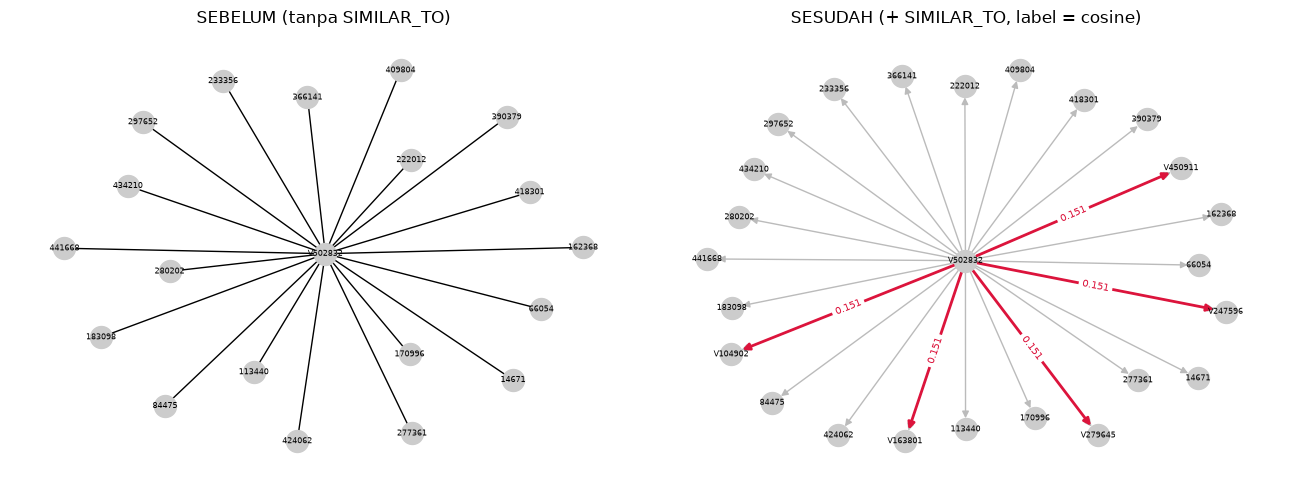

In [16]:
Q_AFTER = f"MATCH p=(a:{LABEL} {{{IDP}:{ref_id}}})-[:SIMILAR_TO]->(b:{LABEL}) RETURN p"; print("Query Browser SESUDAH:", Q_AFTER)
after = cypher(f"MATCH (a:{LABEL} {{{IDP}:$ref}})-[s:SIMILAR_TO]->(b:{LABEL}) RETURN a.{IDP} AS a, b.{IDP} AS b, s.score AS score", ref=ref_id)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
G1 = nx.Graph([(f"{LABEL[0]}{r['a']}", str(r["x"])) for r in before_rows]); nx.draw_networkx(G1, nx.spring_layout(G1, seed=SEED), ax=ax[0], node_size=250, font_size=6, node_color="#ccc")
ax[0].set_title("SEBELUM (tanpa SIMILAR_TO)"); ax[0].axis("off")
G2 = nx.DiGraph([(f"{LABEL[0]}{r['a']}", str(r["x"])) for r in before_rows]); se = []
for r in after: G2.add_edge(f"{LABEL[0]}{r['a']}", f"{LABEL[0]}{r['b']}", score=round(r["score"], 3)); se.append((f"{LABEL[0]}{r['a']}", f"{LABEL[0]}{r['b']}"))
pos = nx.spring_layout(G2, seed=SEED); nx.draw_networkx(G2, pos, ax=ax[1], node_size=250, font_size=6, node_color="#ccc", edge_color="#bbb")
nx.draw_networkx_edges(G2, pos, edgelist=se, ax=ax[1], edge_color="crimson", width=2)
nx.draw_networkx_edge_labels(G2, pos, ax=ax[1], font_size=7, font_color="crimson", edge_labels={e: G2.edges[e]["score"] for e in se})
ax[1].set_title("SESUDAH (+ SIMILAR_TO, label = cosine)"); ax[1].axis("off"); plt.tight_layout(); plt.show()

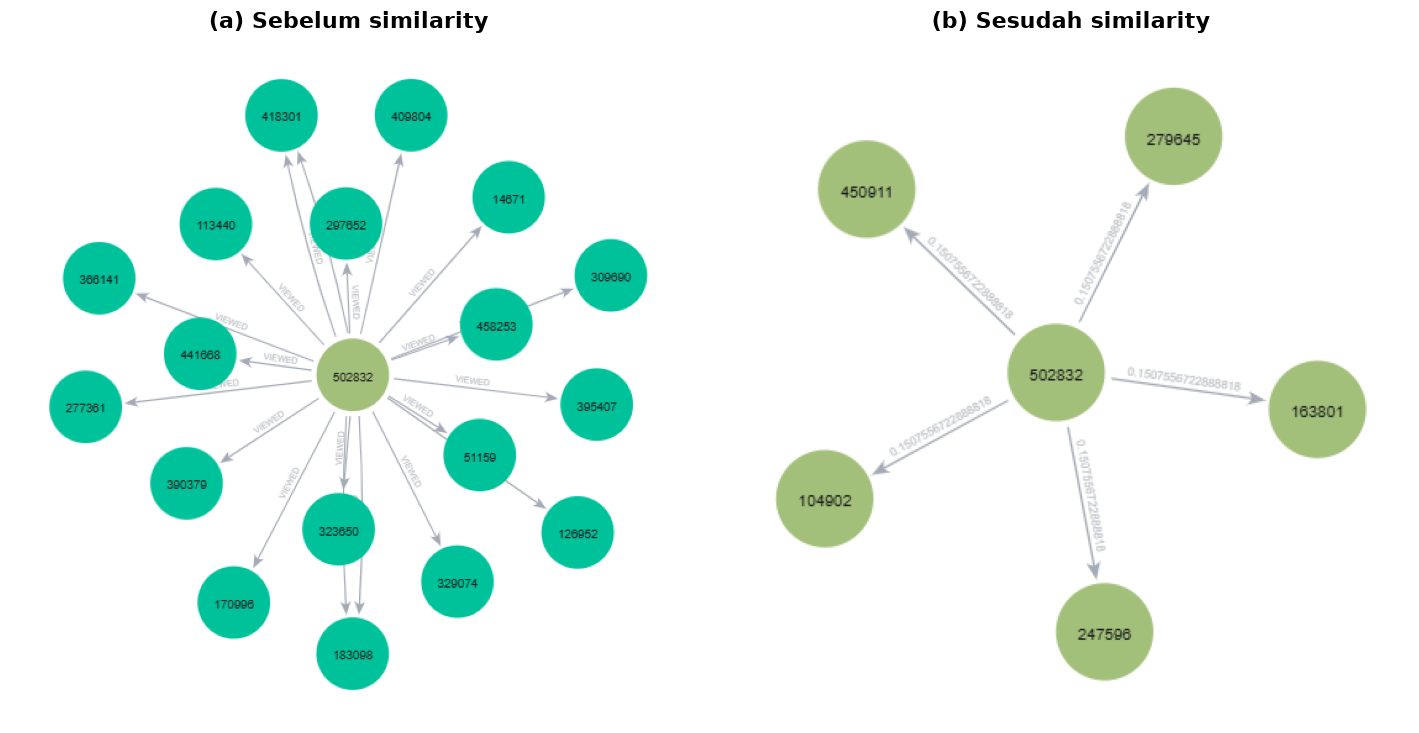

In [17]:
def potong_ruang_kosong(file):
    with Image.open(file) as sumber:
        rgba = sumber.convert("RGBA")
        img = Image.new("RGBA", rgba.size, "white")
        img.alpha_composite(rgba)
        img = img.convert("RGB")
    piksel = np.asarray(img)
    isi = np.any(piksel < 240, axis=2)
    y, x = np.where(isi)

    if len(x):
        margin = 25
        img = img.crop((max(0, int(x.min()) - margin), max(0, int(y.min()) - margin), min(img.width, int(x.max()) + margin + 1), min(img.height, int(y.max()) + margin + 1)))
    return img

files = ["images/neo4j_before.png", "images/neo4j_after.png"]
judul = ["(a) Sebelum similarity", "(b) Sesudah similarity"]
fig, axes = plt.subplots(1, 2, figsize=(12, 6), dpi=120,facecolor="white",constrained_layout=True)
for ax, file, title in zip(axes, files, judul):
    img = potong_ruang_kosong(file)
    lebar, tinggi = img.size
    sisi = max(lebar, tinggi)
    kiri = (sisi - lebar) / 2
    atas = (sisi - tinggi) / 2

    ax.imshow(img,extent=(kiri, kiri + lebar, atas + tinggi, atas))
    ax.set_xlim(0, sisi)
    ax.set_ylim(sisi, 0)
    ax.set_aspect("equal")
    ax.set_title(title, fontsize=13, fontweight="bold", pad=12)
    ax.axis("off")
plt.show()



`Q_BEFORE` menampilkan pola relasi interaksi P1; `Q_AFTER` menampilkan
relasi similarity pada proyeksi terpilih. Keduanya merupakan tampilan pola
berbeda, bukan jaminan bahwa database tidak mengandung SIMILAR_TO saat
query pertama dijalankan. Untuk bukti kronologis, ambil screenshot pertama
sebelum sel penulisan similarity pada run database yang baru diimpor.
Jumlah SIMILAR_TO sebelum dan sesudah tercetak di notebook.
Plot networkx tetap digunakan sebagai visualisasi pendamping.

##### **2.2 Analytics**
**No. 1:** user dipilih acak dengan `np.random.default_rng(SEED)` dari visitor yang ada di P1 **dan** punya item relevan di P2 (reproducible). KNN k=5 memakai proyeksi terpilih (*item-based*: tiap item yang pernah disentuh user diambil 5 item termirip; *user-based*: 5 visitor termirip, item mereka yang belum dilihat user diskor dengan jumlah similarity). 3 teratas = item yang diiklankan; top-5 dipakai untuk metrik. Item dengan skor 0 adalah *fallback* populer (KNN tidak cukup kandidat).

In [18]:
uid = int(np.random.default_rng(SEED).choice(cand)); u_row = int(np.searchsorted(user_ids, uid)); relevant = GT[uid]
recs = recommend(u_row, PROYEKSI)
print(f"User acak (seed={SEED}): visitor {uid} | item di P1={A[u_row].nnz} | item relevan di P2={len(relevant)} | mode={PROYEKSI}-based KNN, k={K}")
if PROYEKSI == "Visitor": print("5 tetangga:", [(int(user_ids[b]), round(s, 4)) for b, s in TOPK["Visitor"]([u_row])[u_row]])
ads = pd.DataFrame(recs, columns=["itemId", "skor"]); ads["sumber"] = np.where(ads.skor > 0, "KNN", "fallback populer")
print("3 item yang DIIKLANKAN:"); display(ads.head(3)); print("Top-5:", ads.itemId.tolist())

User acak (seed=2026): visitor 1208179 | item di P1=14 | item relevan di P2=10 | mode=Visitor-based KNN, k=5
5 tetangga: [(856590, 0.378), (1044686, 0.378), (366386, 0.3086), (583043, 0.3086), (607572, 0.3086)]
3 item yang DIIKLANKAN:


,itemId,skor,sumber
0,26228,0.308607,KNN
1,49621,0.308607,KNN
2,416007,0.308607,KNN


Top-5: [26228, 49621, 416007, 309778, 257040]


**No. 2: Hit@5 dan NDCG@5**

Lima item rekomendasi digunakan untuk evaluasi, sedangkan tiga item pertama
adalah item iklan untuk No. 1b. Angka k=5 adalah jumlah tetangga KNN;
jumlah rekomendasi evaluasi juga 5 tetapi merupakan parameter yang berbeda.

Ground truth mengikuti aturan pada fungsi bantu: item P2 yang ada pada
katalog P1 dan belum pernah diinteraksikan user di P1. Hit@5 bernilai 1 jika
ada minimal satu item relevan pada top-5, selain itu 0. NDCG@5 menggunakan
relevansi biner dan IDCG berdasarkan min(5, jumlah item ground truth).

Hit@5 = 0 pada seorang user adalah hasil yang sah. Seed tidak diubah untuk
memperoleh hit. Rata-rata seluruh user layak ditampilkan sebagai konteks,
bukan pengganti hasil user acak. Metrik mencakup fallback populer ketika
kandidat KNN tidak cukup.

In [19]:
rp, hit, ndcg, dcg, idcg = metrics(ads.itemId.tolist(), relevant)
print("Relevan (P2):", sorted(relevant)[:20]); print("Relevansi per posisi:", rp)
print(f"Hit@5  = {hit}"); print(f"NDCG@5 = {ndcg:.4f}  (DCG={dcg:.4f}, IDCG={idcg:.4f})")
summary = eff.loc[eff["Proyeksi"] == PROYEKSI,
                  ["Proyeksi", "Jumlah user evaluasi", "Hit@5", "NDCG@5"]]
print("Rata-rata seluruh user layak, dari evaluasi No. 6:")
display(summary)
if hit == 0:
    print("Tidak ada item relevan pada top-5 user ini; seed tetap dipertahankan.")
driver.close()

Relevan (P2): [20542, 24154, 114342, 136845, 152346, 207294, 301128, 345330, 354401, 463638]
Relevansi per posisi: [0, 0, 0, 0, 0]
Hit@5  = 0
NDCG@5 = 0.0000  (DCG=0.0000, IDCG=2.9485)
Rata-rata seluruh user layak, dari evaluasi No. 6:


,Proyeksi,Jumlah user evaluasi,Hit@5,NDCG@5
0,Visitor,4244,0.034637,0.015648


Tidak ada item relevan pada top-5 user ini; seed tetap dipertahankan.
